# Credit Card Fraud Detection

## Machine Learning-Based Fraud Detection System

### Project Overview

Credit card fraud detection is a classification problem in which
machine learning techniques are used to identify potentially
fraudulent transactions from legitimate transactions.

This project performs exploratory data analysis, data preprocessing,
class imbalance handling, machine learning model development, and
model evaluation to develop a fraud detection system.

### Dataset

The project uses the Credit Card Fraud Detection dataset containing
transaction-level information and a binary target variable indicating
whether a transaction is fraudulent or legitimate.

# 01. Project Introduction

Credit card fraud is a major challenge in digital financial transactions.
Fraudulent transactions are difficult to identify because they represent
only a small portion of the total transaction data.

This project uses exploratory data analysis and machine learning
techniques to analyze transaction patterns and detect potentially
fraudulent transactions.

# 02. Problem Statement

The objective of this project is to develop a machine learning-based
classification system that can distinguish fraudulent credit card
transactions from legitimate transactions.

The major challenge is the highly imbalanced nature of the dataset,
where fraudulent transactions are much fewer than legitimate
transactions. Therefore, appropriate preprocessing and evaluation
metrics are required.

# 03. Project Objectives

The main objectives of this project are:

- Perform detailed exploratory data analysis.
- Understand the distribution of legitimate and fraudulent transactions.
- Analyze transaction amount and time-related patterns.
- Identify important relationships among features.
- Preprocess the transaction data for machine learning.
- Address the class imbalance problem.
- Train multiple classification models.
- Evaluate models using precision, recall, F1-score, ROC-AUC, and
  precision-recall analysis.
- Analyze model errors and feature importance.
- Generate predictions for unseen transactions.

# 04. Dataset Description

The Credit Card Fraud Detection dataset contains transactions made by
credit card holders. The dataset consists of anonymized numerical
features along with transaction time, transaction amount, and a target
variable named `Class`.

The `Class` variable represents:

- `0` — Legitimate transaction
- `1` — Fraudulent transaction

Most feature names are anonymized as V1, V2, ..., V28 to protect
sensitive information.

In [ ]:
# 05. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

sns.set_theme(style="whitegrid")

In [ ]:
# 06. Load Dataset
df = pd.read_csv("/content/creditcard.csv")

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
# 07. Dataset Overview

df.shape

(31780, 31)

In [ ]:
# 08. Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31780 entries, 0 to 31779
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    31780 non-null  int64  
 1   V1      31780 non-null  float64
 2   V2      31780 non-null  float64
 3   V3      31780 non-null  float64
 4   V4      31780 non-null  float64
 5   V5      31780 non-null  float64
 6   V6      31780 non-null  float64
 7   V7      31779 non-null  float64
 8   V8      31779 non-null  float64
 9   V9      31779 non-null  float64
 10  V10     31779 non-null  float64
 11  V11     31779 non-null  float64
 12  V12     31779 non-null  float64
 13  V13     31779 non-null  float64
 14  V14     31779 non-null  float64
 15  V15     31779 non-null  float64
 16  V16     31779 non-null  float64
 17  V17     31779 non-null  float64
 18  V18     31779 non-null  float64
 19  V19     31779 non-null  float64
 20  V20     31779 non-null  float64
 21  V21     31779 non-null  float64
 22

In [ ]:
# 09. Missing Value Analysis

df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,1
V8,1
V9,1


In [ ]:
# 10. Duplicate Record Analysis

df.duplicated().sum()

np.int64(129)

In [ ]:
# 11. Statistical Summary

df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,31780.000000,31780.000000,31780.000000,31780.000000,31780.000000,31780.000000,31780.000000,31779.000000,31779.000000,31779.000000,...,31779.000000,31779.000000,31779.000000,31779.000000,31779.000000,31779.000000,31779.000000,31779.000000,31779.000000,31779.000000
mean,22329.432410,-0.212640,0.104667,0.721370,0.211236,-0.209710,0.088247,-0.120162,0.031883,0.314021,...,-0.033146,-0.119157,-0.040436,0.008409,0.134365,0.022637,0.012911,0.003384,81.115001,0.003210
std,12184.540274,1.854714,1.547456,1.589832,1.420692,1.408421,1.314428,1.283076,1.264390,1.250651,...,0.778376,0.640252,0.539220,0.591869,0.435709,0.508922,0.390404,0.300394,223.154481,0.056564
min,0.000000,-30.552380,-40.978852,-31.103685,-5.172595,-42.147898,-23.496714,-26.548144,-41.484823,-7.175097,...,-20.262054,-8.593642,-26.751119,-2.836627,-7.495741,-1.338556,-8.567638,-9.617915,0.000000,0.000000
25%,10971.000000,-0.956800,-0.467657,0.257092,-0.702958,-0.807339,-0.651105,-0.597343,-0.159243,-0.482553,...,-0.242905,-0.541636,-0.177032,-0.326931,-0.128724,-0.333026,-0.063132,-0.007594,6.790000,0.000000
50%,27331.000000,-0.246371,0.135141,0.842625,0.198585,-0.243626,-0.167815,-0.071105,0.038210,0.196750,...,-0.087460,-0.094216,-0.050669,0.062628,0.173028,-0.059277,0.008684,0.020795,20.000000,0.000000
75%,32942.000000,1.164230,0.776101,1.468823,1.095675,0.308333,0.474682,0.441280,0.298470,1.063590,...,0.087763,0.289984,0.075411,0.398097,0.417497,0.301347,0.089173,0.076435,73.705000,0.000000
max,36513.000000,1.960497,16.713389,4.101716,13.143668,34.099309,22.529298,36.677268,20.007208,10.392889,...,22.614889,5.805795,13.876221,4.014444,5.525093,3.517346,11.135740,5.678671,7879.420000,1.000000


In [ ]:
# 12. Target Variable Analysis

df["Class"].value_counts()

,count
Class,
0.0,31677
1.0,102


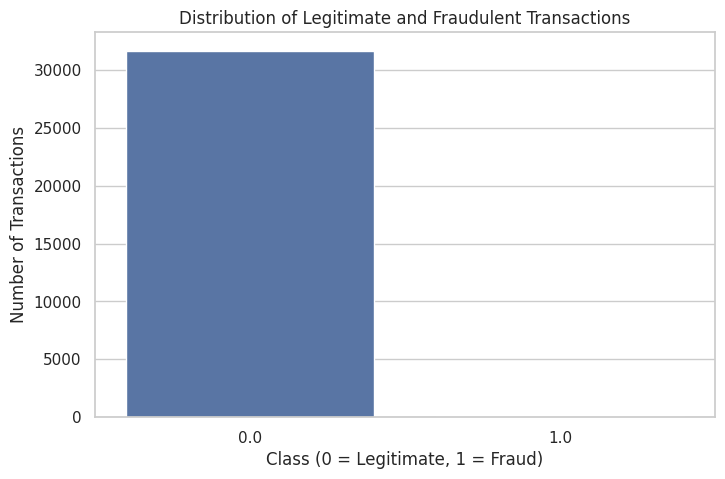

In [ ]:
# 13. Class Distribution

plt.figure(figsize=(8, 5))
sns.countplot(x="Class", data=df)
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [ ]:
# 14. Fraud Percentage Analysis

class_percentage = df["Class"].value_counts(normalize=True) * 100

class_percentage

,proportion
Class,
0.0,99.679033
1.0,0.320967


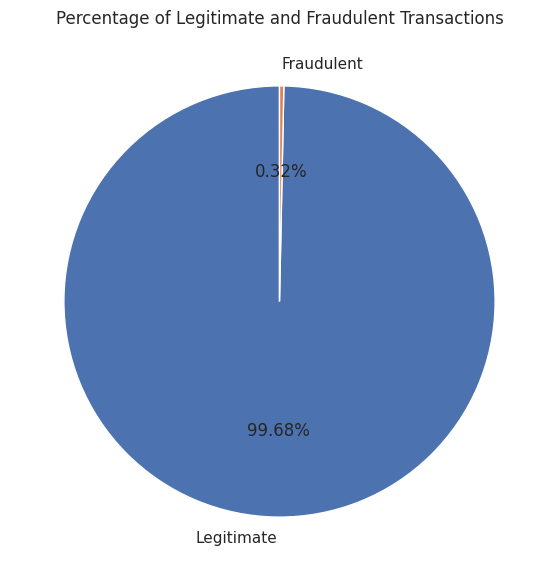

In [ ]:
# 14. Fraud Percentage Visualization

plt.figure(figsize=(7, 7))

plt.pie(
    class_percentage,
    labels=["Legitimate", "Fraudulent"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Percentage of Legitimate and Fraudulent Transactions")

plt.show()

In [ ]:
# 15. Transaction Amount Analysis

df["Amount"].describe()

,Amount
count,31779.000000
mean,81.115001
std,223.154481
min,0.000000
25%,6.790000
50%,20.000000
75%,73.705000
max,7879.420000


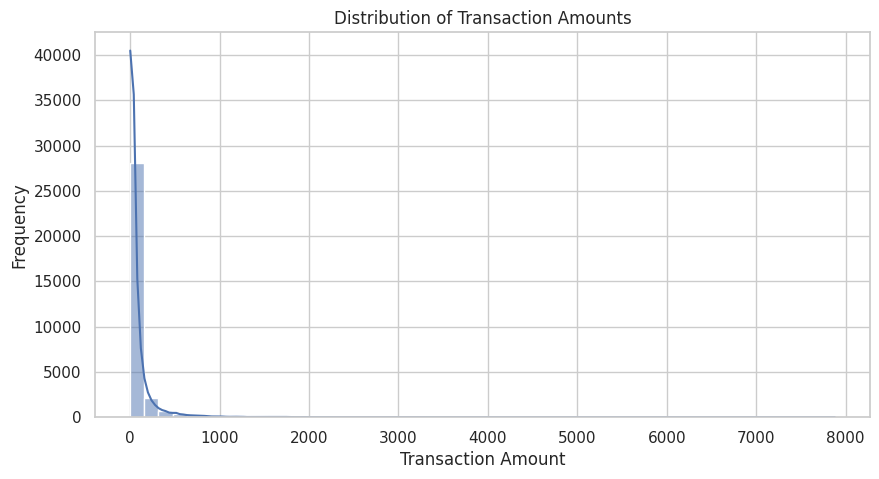

In [ ]:
# 16. Transaction Amount Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    df["Amount"],
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

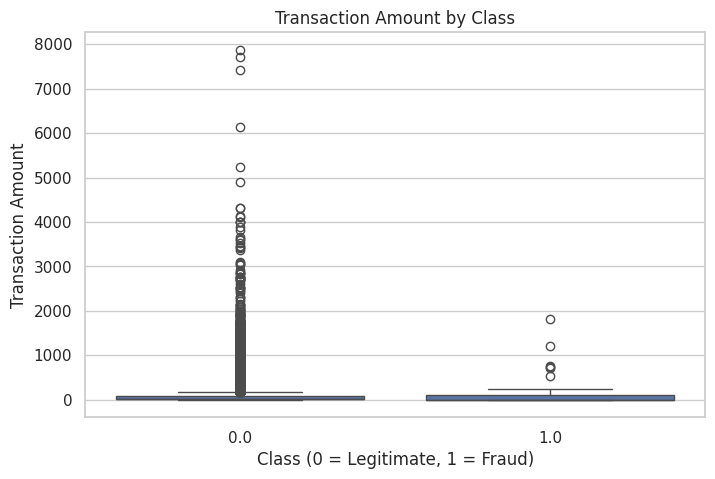

In [ ]:
# 17. Transaction Amount by Class

plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Class",
    y="Amount",
    data=df
)

plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.show()

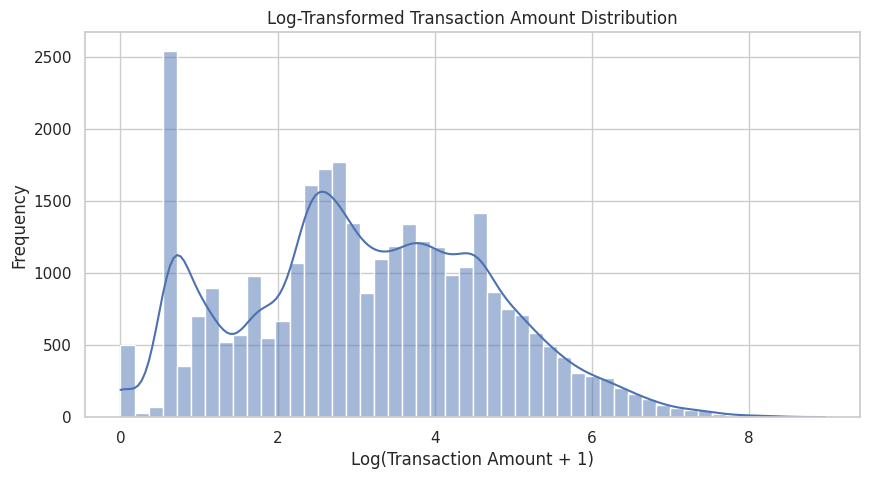

In [ ]:
# 18. Log-Transformed Transaction Amount

df["Log_Amount"] = np.log1p(df["Amount"])

plt.figure(figsize=(10, 5))

sns.histplot(
    df["Log_Amount"],
    bins=50,
    kde=True
)

plt.title("Log-Transformed Transaction Amount Distribution")
plt.xlabel("Log(Transaction Amount + 1)")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# 19. Transaction Time Analysis

df["Time"].describe()

,Time
count,31780.000000
mean,22329.432410
std,12184.540274
min,0.000000
25%,10971.000000
50%,27331.000000
75%,32942.000000
max,36513.000000


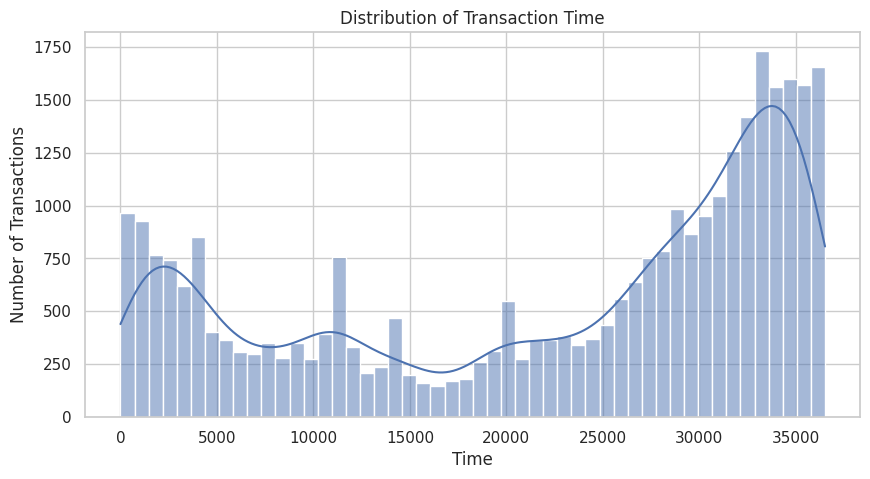

In [ ]:
# 20. Transaction Time Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    df["Time"],
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time")
plt.ylabel("Number of Transactions")

plt.show()

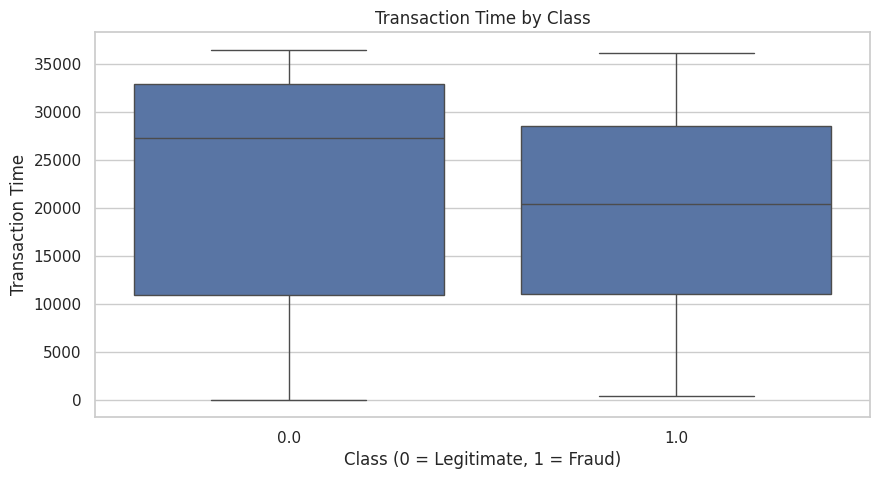

In [ ]:
# 21. Transaction Time by Class

plt.figure(figsize=(10, 5))

sns.boxplot(
    x="Class",
    y="Time",
    data=df
)

plt.title("Transaction Time by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Time")

plt.show()

In [ ]:
# 22. Feature Distribution Analysis

feature_columns = [f"V{i}" for i in range(1, 29)]

df[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
V1,31780.0,-0.212640,1.854714,-30.552380,-0.956800,-0.246371,1.164230,1.960497
V2,31780.0,0.104667,1.547456,-40.978852,-0.467657,0.135141,0.776101,16.713389
V3,31780.0,0.721370,1.589832,-31.103685,0.257092,0.842625,1.468823,4.101716
V4,31780.0,0.211236,1.420692,-5.172595,-0.702958,0.198585,1.095675,13.143668
V5,31780.0,-0.209710,1.408421,-42.147898,-0.807339,-0.243626,0.308333,34.099309
V6,31780.0,0.088247,1.314428,-23.496714,-0.651105,-0.167815,0.474682,22.529298
V7,31779.0,-0.120162,1.283076,-26.548144,-0.597343,-0.071105,0.441280,36.677268
V8,31779.0,0.031883,1.264390,-41.484823,-0.159243,0.038210,0.298470,20.007208
V9,31779.0,0.314021,1.250651,-7.175097,-0.482553,0.196750,1.063590,10.392889
V10,31779.0,-0.103681,1.150799,-14.166795,-0.581112,-0.155167,0.343484,12.701539


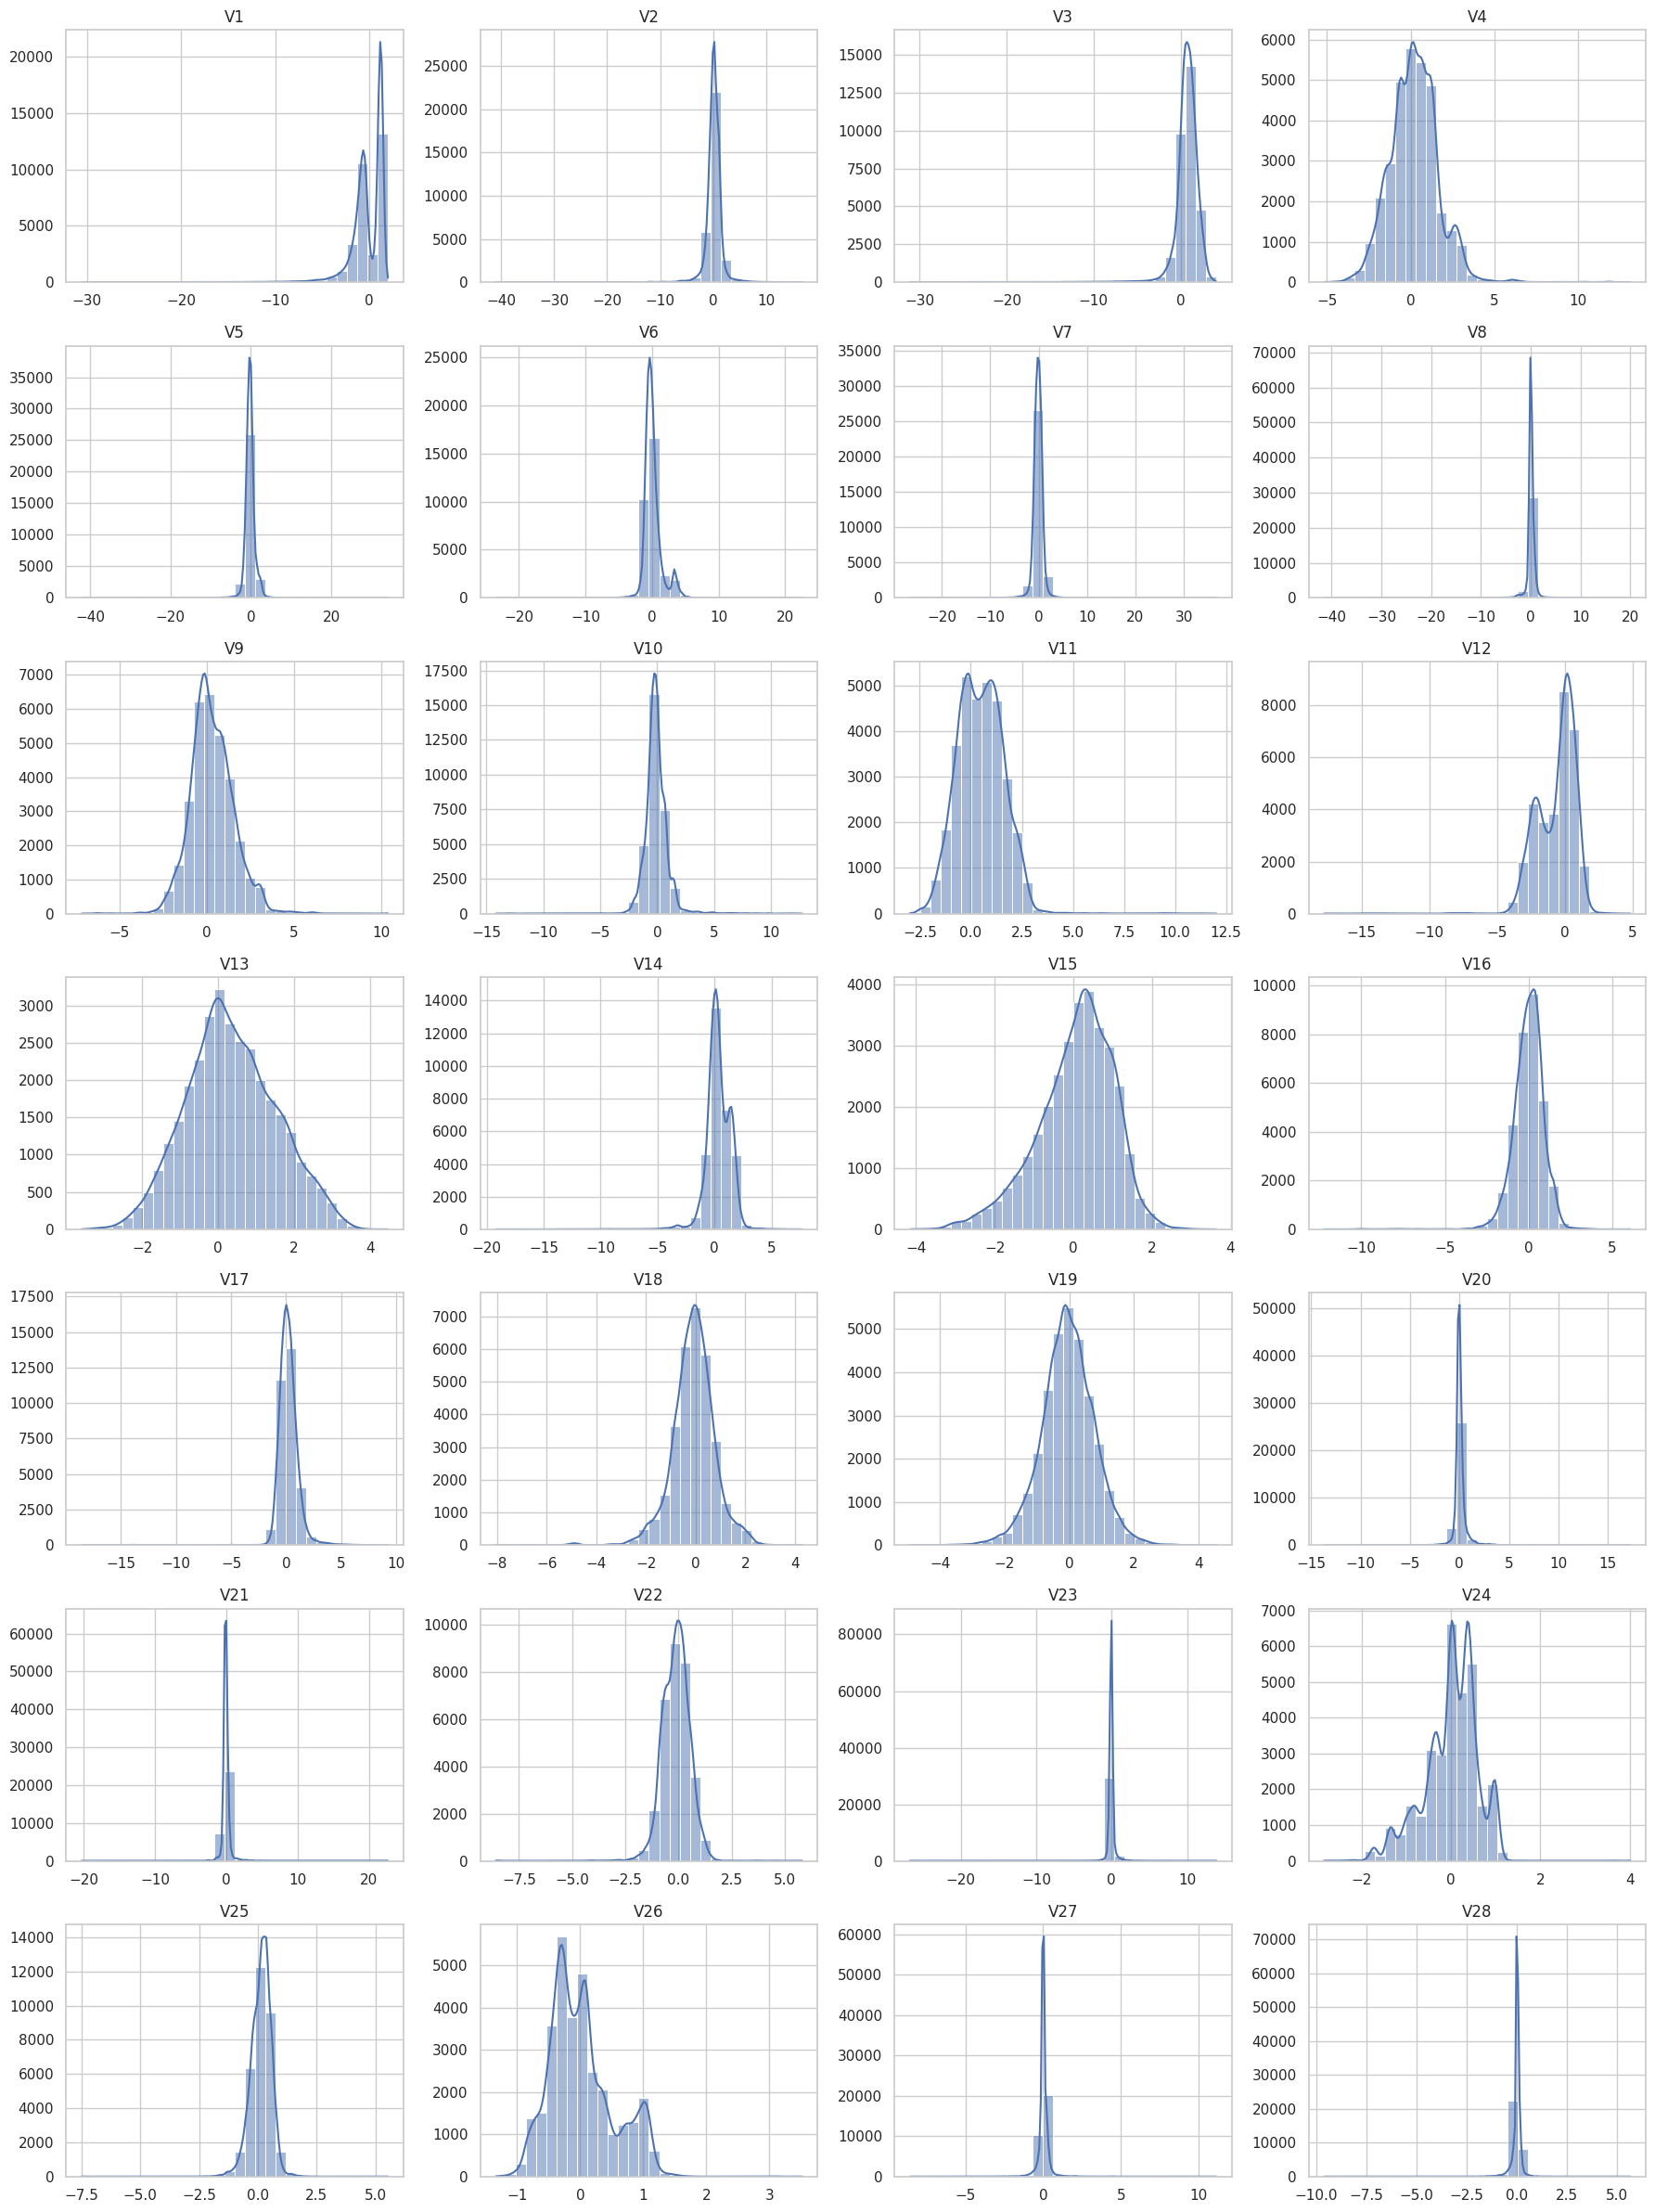

In [ ]:
# 23. V1–V28 Feature Distributions

fig, axes = plt.subplots(7, 4, figsize=(18, 24))

for i, feature in enumerate(feature_columns):
    sns.histplot(
        df[feature],
        bins=30,
        kde=True,
        ax=axes[i // 4, i % 4]
    )

    axes[i // 4, i % 4].set_title(feature)
    axes[i // 4, i % 4].set_xlabel("")
    axes[i // 4, i % 4].set_ylabel("")

plt.tight_layout()
plt.show()

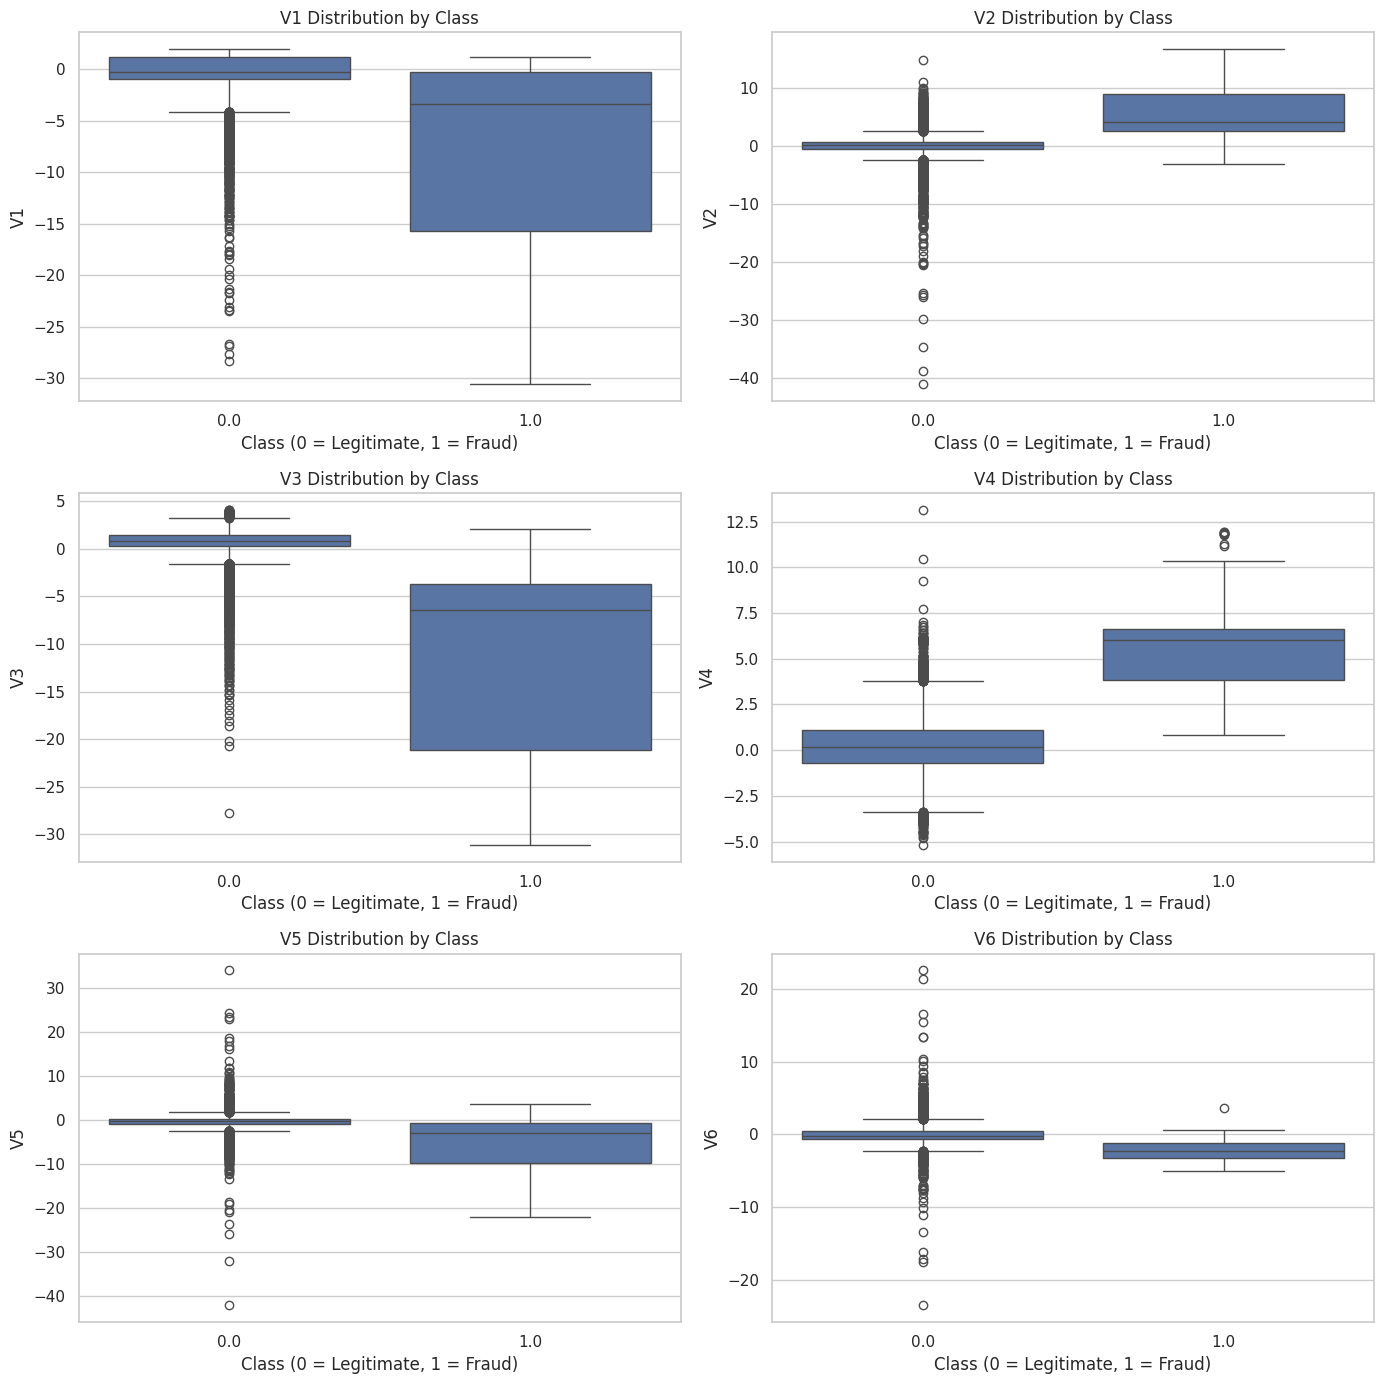

In [ ]:
# 24. Fraud vs Legitimate Feature Analysis

selected_features = ["V1", "V2", "V3", "V4", "V5", "V6"]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for i, feature in enumerate(selected_features):
    sns.boxplot(
        x="Class",
        y=feature,
        data=df,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f"{feature} Distribution by Class"
    )

    axes[i // 2, i % 2].set_xlabel(
        "Class (0 = Legitimate, 1 = Fraud)"
    )

plt.tight_layout()
plt.show()

In [ ]:
# 25. Outlier Analysis

Q1 = df[feature_columns].quantile(0.25)
Q3 = df[feature_columns].quantile(0.75)

IQR = Q3 - Q1

outlier_counts = (
    (df[feature_columns] < (Q1 - 1.5 * IQR)) |
    (df[feature_columns] > (Q3 + 1.5 * IQR))
).sum()

outlier_counts.sort_values(ascending=False)

,0
V28,5764
V27,4444
V8,3072
V20,3062
V6,2726
V23,2301
V21,2093
V5,2017
V2,1694
V10,1414


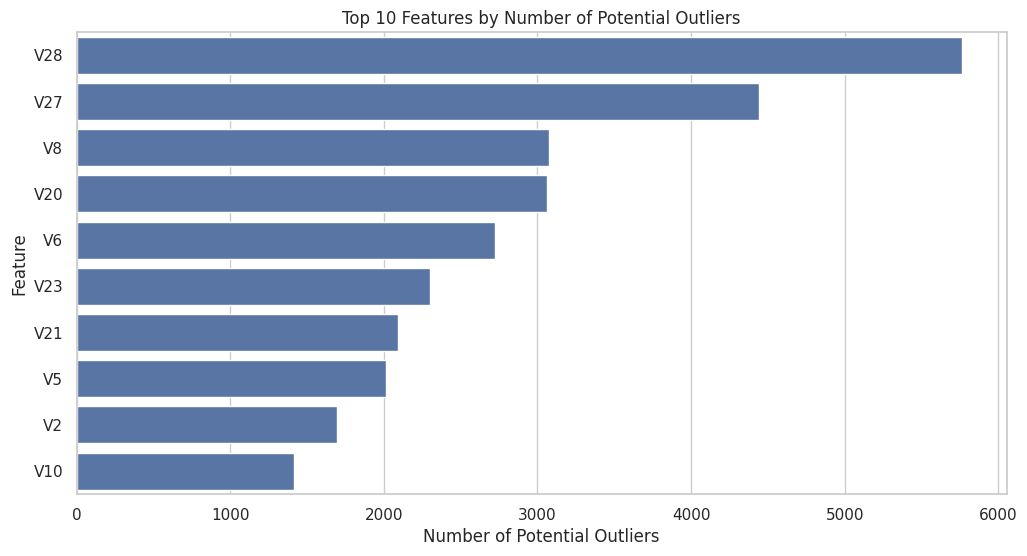

In [ ]:
# 25. Outlier Visualization

top_outlier_features = outlier_counts.nlargest(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_outlier_features.values,
    y=top_outlier_features.index
)

plt.title("Top 10 Features by Number of Potential Outliers")
plt.xlabel("Number of Potential Outliers")
plt.ylabel("Feature")

plt.show()

In [ ]:
# 26. Correlation Analysis

correlation_matrix = df.corr()

correlation_matrix["Class"].sort_values(ascending=False)

,Class
Class,1.000000
V11,0.248451
V4,0.228266
V2,0.214232
V8,0.173806
V27,0.116058
V20,0.054333
V21,0.049213
V19,0.034226
V25,0.023449


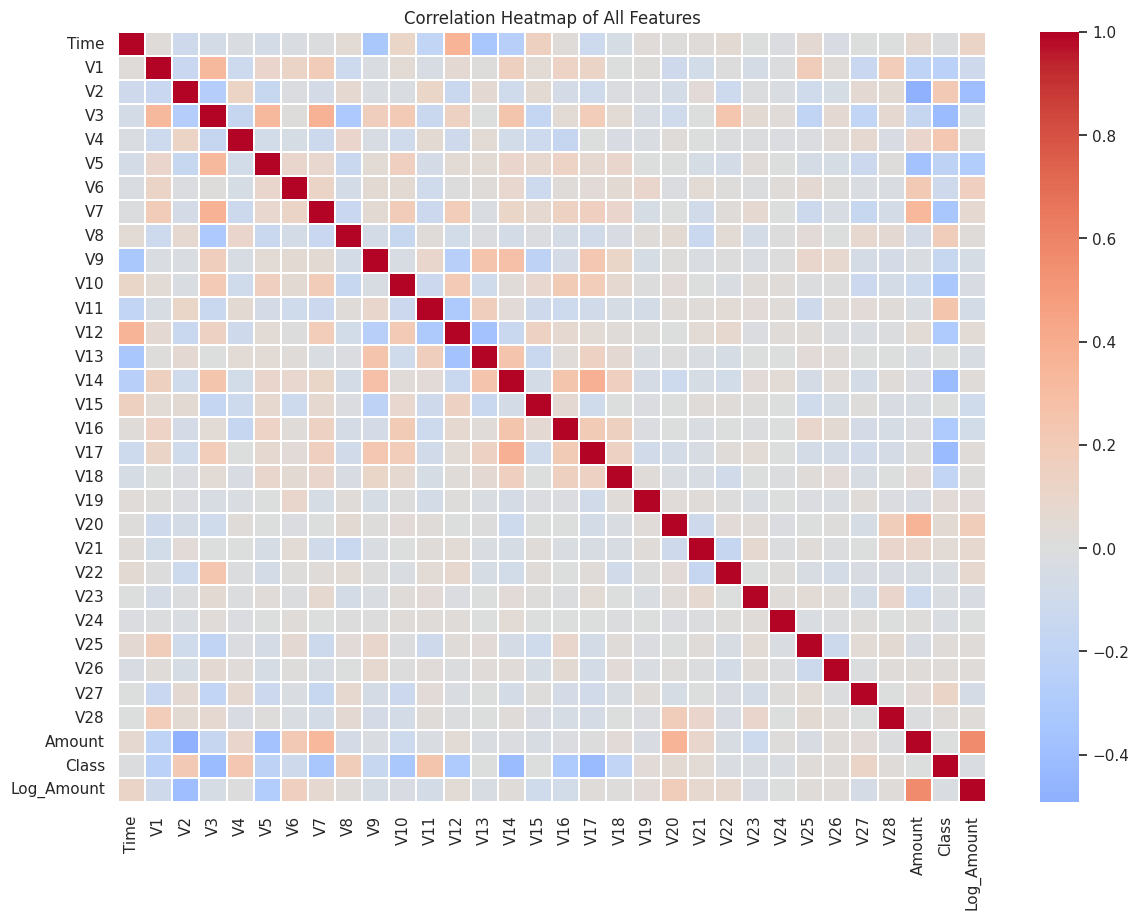

In [ ]:
# 27. Full Correlation Heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of All Features")
plt.show()

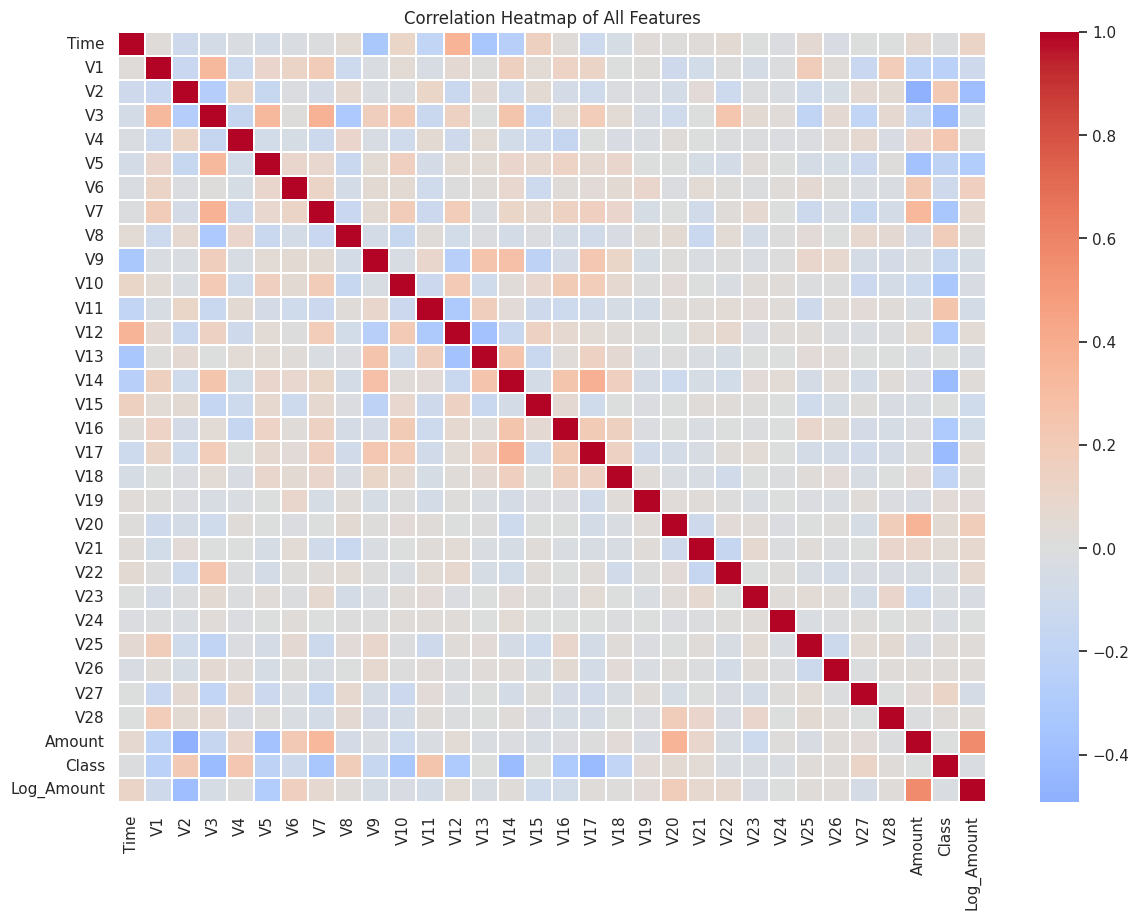

In [ ]:
# 27. Full Correlation Heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of All Features")
plt.show()

In [ ]:
# 28. Target Variable Correlations

class_correlation = (
    correlation_matrix["Class"]
    .drop("Class")
    .sort_values()
)

class_correlation

,Class
V17,-0.424445
V3,-0.419623
V14,-0.411156
V7,-0.338202
V10,-0.328166
V12,-0.304900
V16,-0.299946
V1,-0.230946
V5,-0.214335
V18,-0.184329


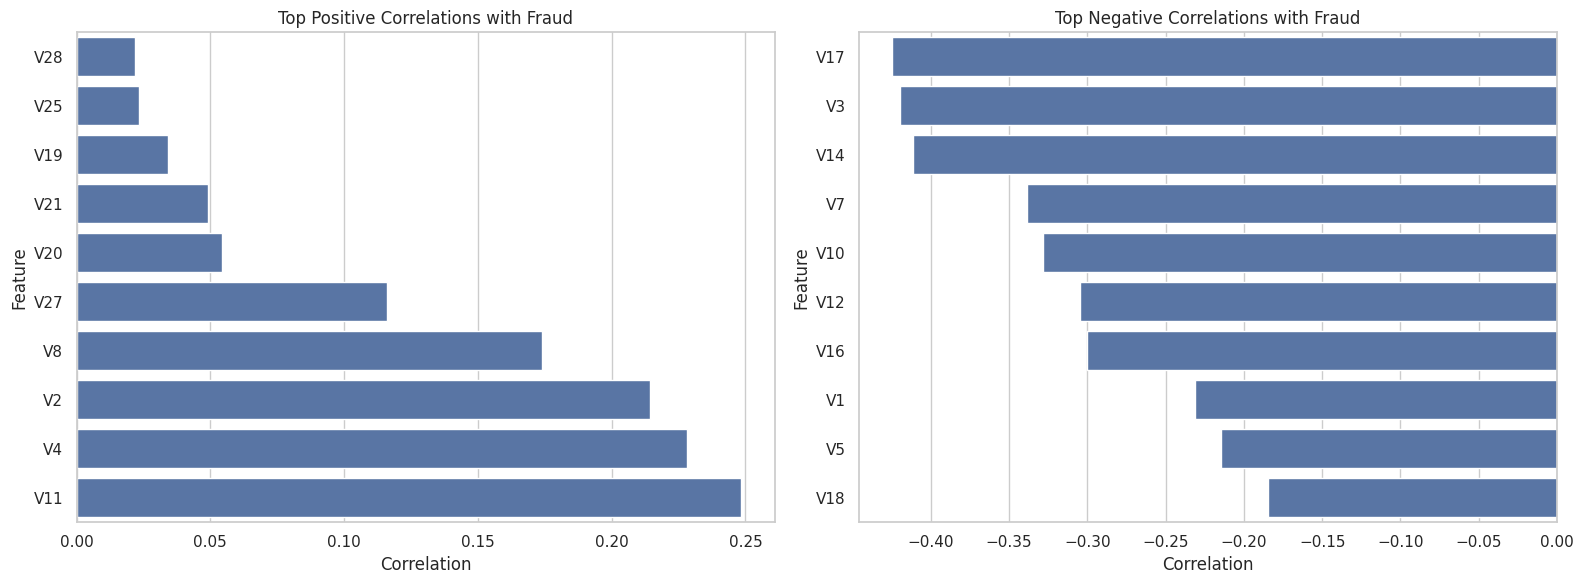

In [ ]:
# 29. Top Positive and Negative Correlations

top_positive = class_correlation.tail(10)

top_negative = class_correlation.head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=top_positive.values,
    y=top_positive.index,
    ax=axes[0]
)

axes[0].set_title("Top Positive Correlations with Fraud")
axes[0].set_xlabel("Correlation")
axes[0].set_ylabel("Feature")

sns.barplot(
    x=top_negative.values,
    y=top_negative.index,
    ax=axes[1]
)

axes[1].set_title("Top Negative Correlations with Fraud")
axes[1].set_xlabel("Correlation")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
# 29A. Fraud Transaction Statistics

fraud_data = df[df["Class"] == 1]

print("Number of fraudulent transactions:", len(fraud_data))
print("Average fraud amount:", fraud_data["Amount"].mean())
print("Maximum fraud amount:", fraud_data["Amount"].max())
print("Minimum fraud amount:", fraud_data["Amount"].min())

Number of fraudulent transactions: 102
Average fraud amount: 91.23745098039213
Maximum fraud amount: 1809.68
Minimum fraud amount: 0.0


In [ ]:
# 29B. Amount Statistics by Class

amount_statistics = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

amount_statistics

,count,mean,median,std,min,max
Class,,,,,,
0.0,31677,81.082407,20.00,223.072655,0.0,7879.42
1.0,102,91.237451,3.44,248.270971,0.0,1809.68


In [ ]:
# 29C. Transaction Time Statistics by Class

time_statistics = df.groupby("Class")["Time"].agg(
    ["mean", "median", "std", "min", "max"]
)

time_statistics

,mean,median,std,min,max
Class,,,,,
0.0,22335.407141,27345.0,12190.110643,0,36513
1.0,20334.872549,20391.5,10139.018408,406,36170


In [ ]:
# 29D. Feature Means by Class

class_feature_means = df.groupby("Class")[feature_columns].mean().T

class_feature_means

Class,0.0,1.0
V1,-0.188381,-7.761095
V2,0.085855,5.946853
V3,0.759238,-11.035230
V4,0.192821,5.926171
V5,-0.192581,-5.529543
V6,0.095930,-2.295415
V7,-0.095538,-7.767215
V8,0.019413,3.904551
V9,0.324683,-2.997290
V10,-0.082251,-6.758838


In [ ]:
# 29E. Feature Mean Difference

feature_difference = (
    class_feature_means[1] - class_feature_means[0]
).sort_values(
    key=abs,
    ascending=False
)

feature_difference.head(15)

,0
V3,-11.794469
V14,-8.728358
V17,-8.304404
V12,-7.856284
V7,-7.671677
V1,-7.572714
V10,-6.676586
V2,5.860998
V4,5.733350
V5,-5.336962


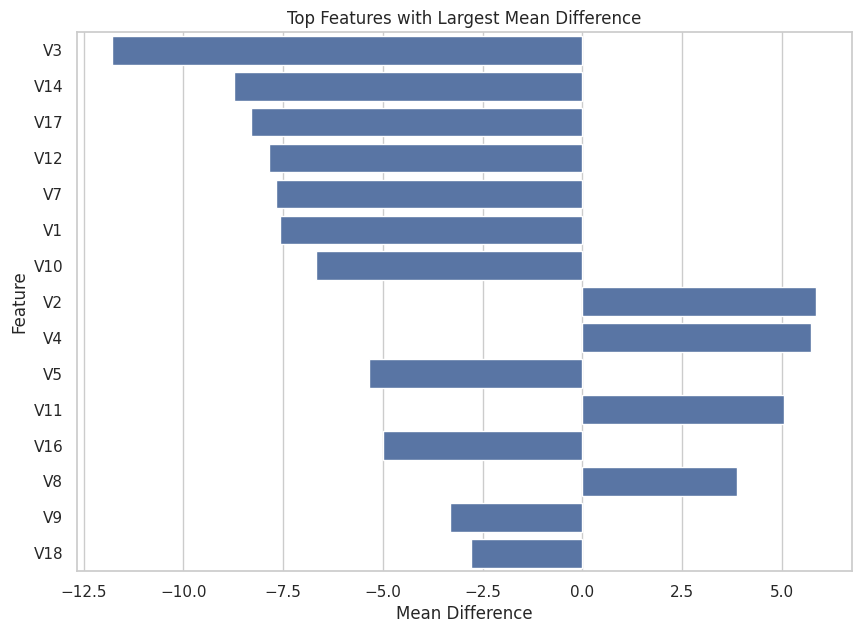

In [ ]:
# 29F. Largest Feature Differences Between Classes

top_differences = feature_difference.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_differences.values,
    y=top_differences.index
)

plt.title("Top Features with Largest Mean Difference")
plt.xlabel("Mean Difference")
plt.ylabel("Feature")

plt.show()

In [ ]:
# 30. Data Preprocessing

df_model = df.copy()

df_model.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Log_Amount
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0,5.014760
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0,1.305626
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0,5.939276
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0,4.824306
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0,4.262539


In [ ]:
# 31. Feature and Target Separation

X = df_model.drop("Class", axis=1)
y = df_model["Class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (31780, 31)
Target shape: (31780,)


In [ ]:
# 32. Feature Scaling

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Log_Amount
0,-1.832632,-0.618524,-0.114672,1.141633,0.821387,-0.091317,0.284646,0.280393,0.052844,0.039793,...,0.019065,0.620068,-0.129889,0.098873,-0.013370,-0.416086,0.309036,-0.081353,0.306989,1.173874
1,-1.832632,0.757270,0.104356,-0.349030,0.166765,0.191514,-0.129798,0.032234,0.042091,-0.455327,...,-0.247479,-0.811436,0.262836,-0.588409,0.075293,0.202898,-0.056082,0.037750,-0.351444,-1.147126
2,-1.832550,-0.617740,-0.933695,0.661614,0.118637,-0.208384,1.302680,0.710509,0.170672,-1.462201,...,0.361199,1.391404,1.761550,-1.178809,-1.060372,-0.317801,-0.174857,-0.210182,1.333380,1.752393
3,-1.832550,-0.406339,-0.187338,0.674058,-0.756353,0.141580,0.881733,0.278843,0.273300,-1.360149,...,-0.096554,0.194348,-0.277969,-2.000446,1.177434,-0.480564,0.127592,0.193326,0.189939,1.054697
4,-1.832468,-0.509840,0.499583,0.520407,0.135005,-0.140218,0.005839,0.555784,-0.239183,0.402771,...,0.030469,1.432950,-0.179932,0.224475,-0.781208,0.942507,0.528975,0.704981,-0.049854,0.703170


In [ ]:
# 33. Train-Test Split

X_scaled_cleaned = X_scaled.dropna()
y_cleaned = y.loc[X_scaled_cleaned.index]

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_cleaned,
    y_cleaned,
    test_size=0.20,
    random_state=42,
    stratify=y_cleaned
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (25423, 31)
Testing features: (6356, 31)
Training target: (25423,)
Testing target: (6356,)


In [ ]:
# 33A. Training and Testing Class Distribution

print("Training set:")
print(y_train.value_counts())

print("\nTesting set:")
print(y_test.value_counts())

Training set:
Class
0.0    25341
1.0       82
Name: count, dtype: int64

Testing set:
Class
0.0    6336
1.0      20
Name: count, dtype: int64


In [ ]:
# 33B. Training and Testing Class Proportion

train_distribution = y_train.value_counts(normalize=True) * 100
test_distribution = y_test.value_counts(normalize=True) * 100

distribution_comparison = pd.DataFrame({
    "Training (%)": train_distribution,
    "Testing (%)": test_distribution
})

distribution_comparison

,Training (%),Testing (%)
Class,,
0.0,99.677457,99.685337
1.0,0.322543,0.314663


In [ ]:
# 34. Class Imbalance Handling

y_train.value_counts()

,count
Class,
0.0,25341
1.0,82


In [ ]:
# 35. Class Weight Approach

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
# 36. SMOTE

from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

y_train_smote.value_counts()

,count
Class,
0.0,25341
1.0,25341


In [ ]:
# 36A. Class Distribution Before and After SMOTE

before_smote = y_train.value_counts()
after_smote = y_train_smote.value_counts()

smote_comparison = pd.DataFrame({
    "Before SMOTE": before_smote,
    "After SMOTE": after_smote
})

smote_comparison

,Before SMOTE,After SMOTE
Class,,
0.0,25341,25341
1.0,82,25341


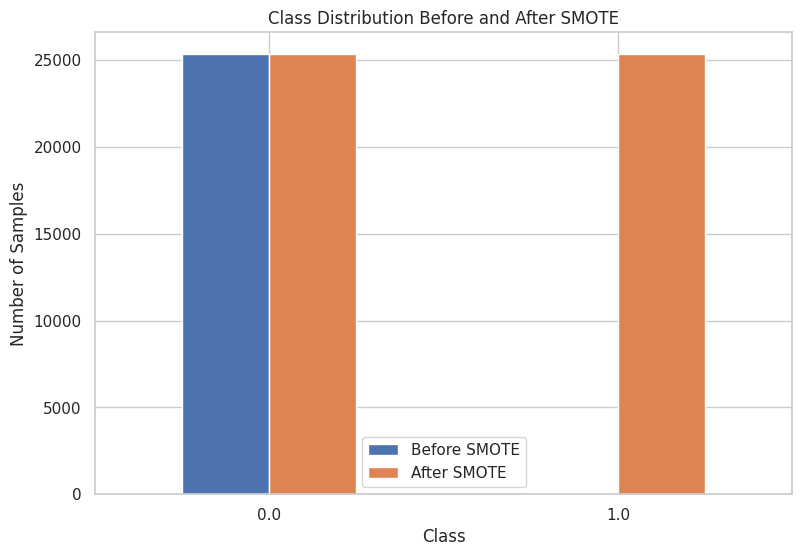

In [ ]:
# 36B. SMOTE Class Distribution Visualization

smote_comparison.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Class Distribution Before and After SMOTE")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.legend()

plt.show()

In [ ]:
# 37. Model Training Setup

models = {}

In [ ]:
# 38. Logistic Regression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_smote,
    y_train_smote
)

models["Logistic Regression"] = logistic_model

In [ ]:
# 39. Decision Tree

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(
    X_train_smote,
    y_train_smote
)

models["Decision Tree"] = decision_tree_model

In [ ]:
# 40. Random Forest

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_smote,
    y_train_smote
)

models["Random Forest"] = random_forest_model

In [ ]:
# 41. Gradient Boosting

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

gradient_boosting_model.fit(
    X_train_smote,
    y_train_smote
)

models["Gradient Boosting"] = gradient_boosting_model

In [ ]:
# 41A. Model Training Summary

for name, model in models.items():
    print(f"{name}: Model trained successfully")

Logistic Regression: Model trained successfully
Decision Tree: Model trained successfully
Random Forest: Model trained successfully
Gradient Boosting: Model trained successfully


In [ ]:
# 42. Model Evaluation

evaluation_results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.984424,0.156522,0.90,0.266667,0.983404
1,Decision Tree,0.998269,0.680000,0.85,0.755556,0.924369
2,Random Forest,0.999056,0.850000,0.85,0.850000,0.972640
3,Gradient Boosting,0.999213,0.826087,0.95,0.883721,0.992479


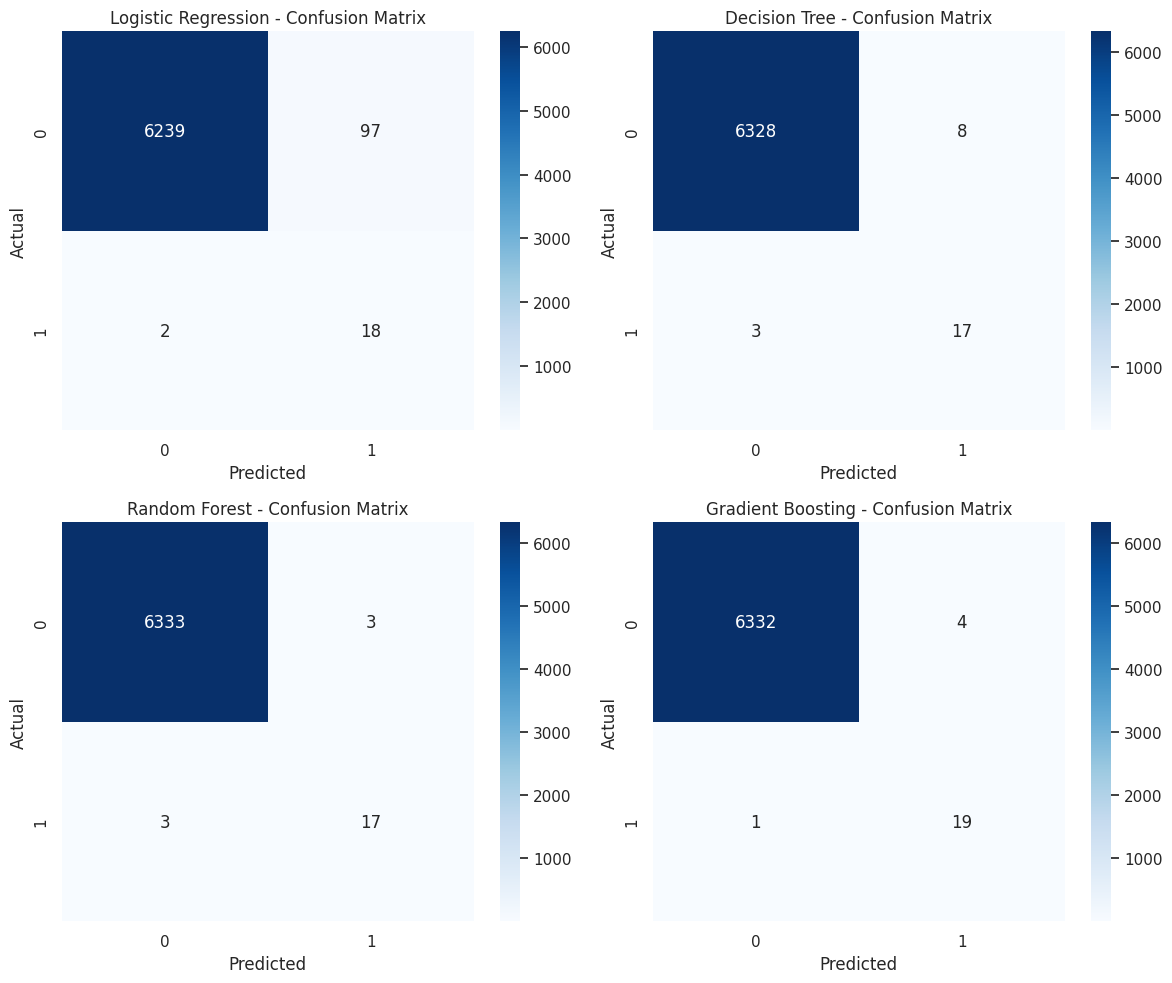

In [ ]:
# 43. Confusion Matrices

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(f"{name} - Confusion Matrix")
    axes[i // 2, i % 2].set_xlabel("Predicted")
    axes[i // 2, i % 2].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
# 43A. Classification Reports

for name, model in models.items():
    y_pred = model.predict(X_test)

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Legitimate", "Fraudulent"]
        )
    )

Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99      6336
  Fraudulent       0.16      0.90      0.27        20

    accuracy                           0.98      6356
   macro avg       0.58      0.94      0.63      6356
weighted avg       1.00      0.98      0.99      6356

Decision Tree
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      6336
  Fraudulent       0.68      0.85      0.76        20

    accuracy                           1.00      6356
   macro avg       0.84      0.92      0.88      6356
weighted avg       1.00      1.00      1.00      6356

Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      6336
  Fraudulent       0.85      0.85      0.85        20

    accuracy                           1.00      6356
   macro avg       0.92      0.92      0.92      6356
weighted avg       1.00   

In [ ]:
# 44. Precision

precision_results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)

    precision_results[name] = precision_score(
        y_test,
        y_pred
    )

precision_df = pd.DataFrame(
    precision_results.items(),
    columns=["Model", "Precision"]
)

precision_df

,Model,Precision
0,Logistic Regression,0.156522
1,Decision Tree,0.680000
2,Random Forest,0.850000
3,Gradient Boosting,0.826087


In [ ]:
# 45. Recall

recall_results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)

    recall_results[name] = recall_score(
        y_test,
        y_pred
    )

recall_df = pd.DataFrame(
    recall_results.items(),
    columns=["Model", "Recall"]
)

recall_df

,Model,Recall
0,Logistic Regression,0.90
1,Decision Tree,0.85
2,Random Forest,0.85
3,Gradient Boosting,0.95


In [ ]:
# 46. F1 Score

f1_results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)

    f1_results[name] = f1_score(
        y_test,
        y_pred
    )

f1_df = pd.DataFrame(
    f1_results.items(),
    columns=["Model", "F1 Score"]
)

f1_df

,Model,F1 Score
0,Logistic Regression,0.266667
1,Decision Tree,0.755556
2,Random Forest,0.850000
3,Gradient Boosting,0.883721


In [ ]:
# 47. ROC-AUC

roc_auc_results = {}

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    roc_auc_results[name] = roc_auc_score(
        y_test,
        y_prob
    )

roc_auc_df = pd.DataFrame(
    roc_auc_results.items(),
    columns=["Model", "ROC-AUC"]
)

roc_auc_df

,Model,ROC-AUC
0,Logistic Regression,0.983404
1,Decision Tree,0.924369
2,Random Forest,0.972640
3,Gradient Boosting,0.992479


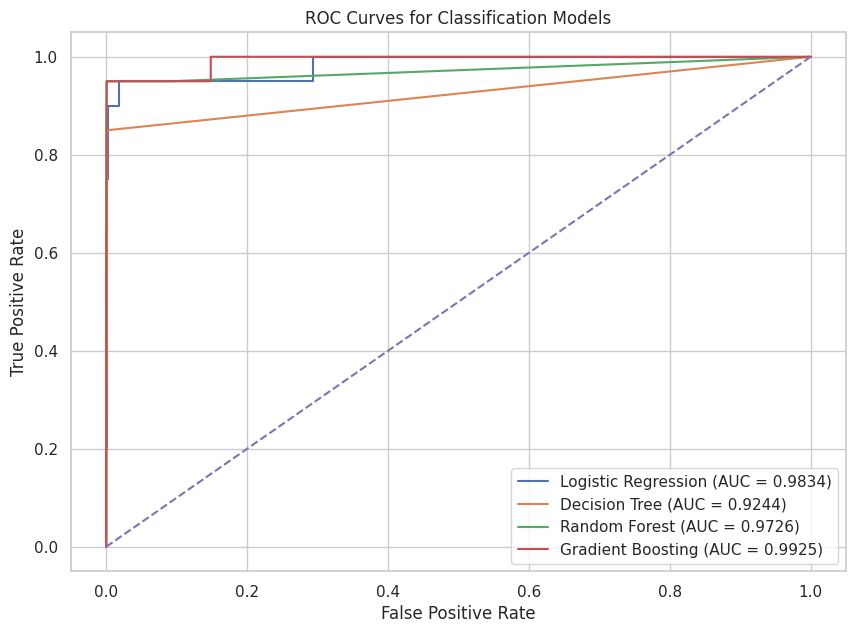

In [ ]:
# 48. ROC Curves

plt.figure(figsize=(10, 7))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curves for Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

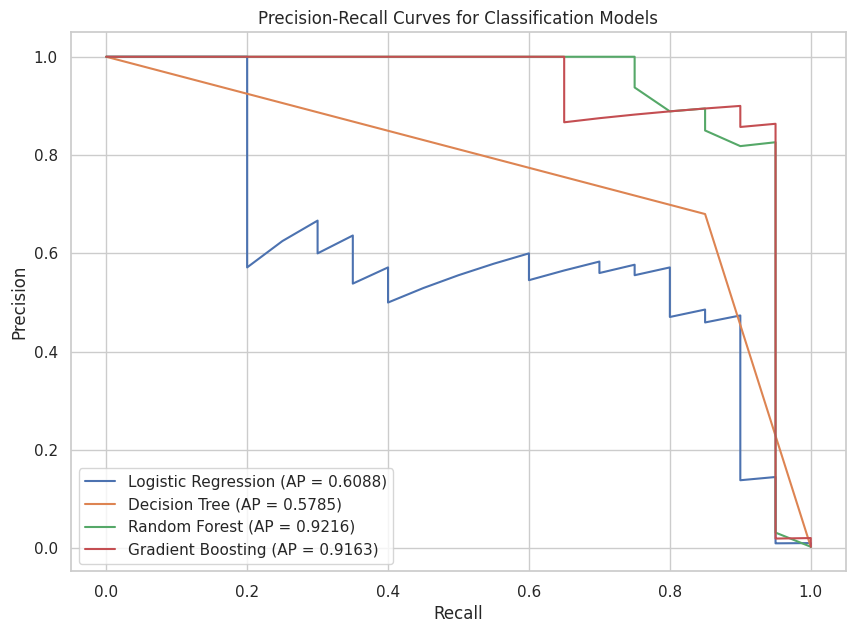

In [ ]:
# 49. Precision-Recall Curves

plt.figure(figsize=(10, 7))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test,
        y_prob
    )

    average_precision = average_precision_score(
        y_test,
        y_prob
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {average_precision:.4f})"
    )

plt.title("Precision-Recall Curves for Classification Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

In [ ]:
# 50. Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
14,V14,0.197826
10,V10,0.137663
3,V3,0.116789
4,V4,0.096665
11,V11,0.075341
17,V17,0.072152
12,V12,0.067122
2,V2,0.033400
7,V7,0.027554
16,V16,0.024783


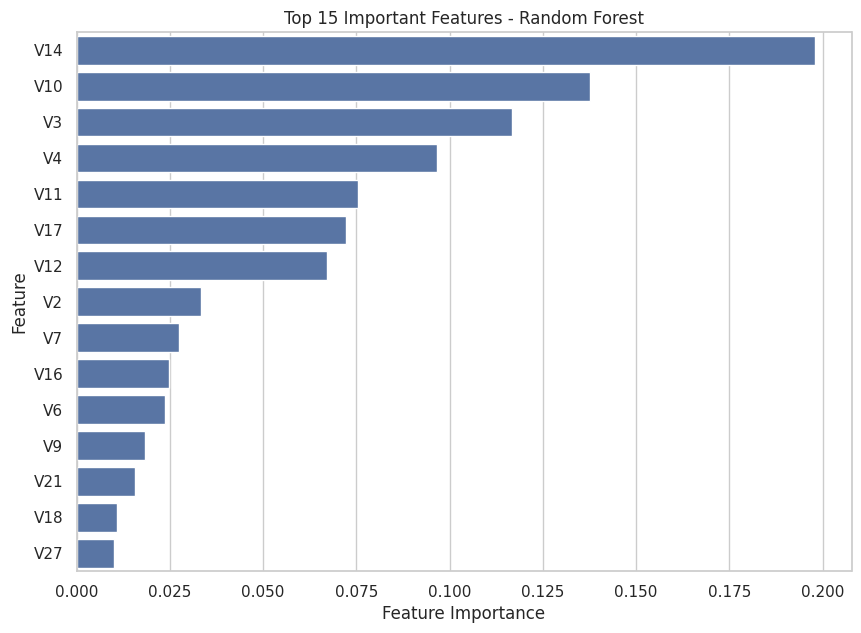

In [ ]:
# 50. Feature Importance Visualization

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    x="Importance",
    y="Feature",
    data=top_features
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

In [ ]:
# 51. Error Analysis

error_analysis = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    false_positives = ((y_test == 0) & (y_pred == 1)).sum()
    false_negatives = ((y_test == 1) & (y_pred == 0)).sum()

    error_analysis.append({
        "Model": name,
        "False Positives": false_positives,
        "False Negatives": false_negatives
    })

error_analysis_df = pd.DataFrame(error_analysis)

error_analysis_df

,Model,False Positives,False Negatives
0,Logistic Regression,97,2
1,Decision Tree,8,3
2,Random Forest,3,3
3,Gradient Boosting,4,1


In [ ]:
# 51A. False Negative Analysis

final_model = random_forest_model

y_pred = final_model.predict(X_test)

false_negative_indices = X_test[
    (y_test == 1) & (y_pred == 0)
].index

false_negative_samples = df_model.loc[
    false_negative_indices
]

false_negative_samples.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Log_Amount
4920,4462,-2.303350,1.759247,-0.359745,2.330243,-0.821628,-0.075788,0.562320,-0.399147,-0.238253,...,-0.932391,0.172726,-0.087330,-0.156114,-0.542628,0.039566,-0.153029,239.93,1.0,5.484506
10498,17230,-0.469327,1.111453,2.041003,1.731595,0.135147,-0.093625,0.266155,0.082988,0.580255,...,0.592670,-0.053596,0.320748,-0.369121,-0.136605,-0.100845,0.039347,3.93,1.0,1.595339
14338,25426,1.125336,1.130146,-0.962975,2.675688,0.990075,-0.243318,0.316192,0.122960,-1.143343,...,-0.521934,-0.112376,-0.592077,0.520791,0.043354,0.015159,0.063612,3.76,1.0,1.560248


In [ ]:
# 51B. False Positive Analysis

false_positive_indices = X_test[
    (y_test == 0) & (y_pred == 1)
].index

false_positive_samples = df_model.loc[
    false_positive_indices
]

false_positive_samples.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Log_Amount
14026,24955,-15.239440,10.096638,-18.579969,6.161424,-12.054621,-4.019253,-13.648636,10.250927,-2.868167,...,-1.227214,-0.558447,0.035438,0.941530,-0.275561,1.700285,0.540294,89.99,0.0,4.510750
8464,11347,1.261630,2.797779,-5.458663,3.844880,5.435051,1.844395,1.203394,0.323753,-1.416101,...,-0.972494,-0.592696,0.280911,1.572414,0.491744,-0.025573,0.152650,1.00,0.0,0.693147
14920,26217,-17.950631,11.067069,-20.742660,6.075531,-13.389765,-4.532888,-15.188146,12.101062,-4.026880,...,-1.275675,-0.705046,0.102040,1.177477,-0.238730,1.554463,0.547948,1.00,0.0,0.693147


In [ ]:
# 52. Sample Predictions

sample_predictions = X_test.head(10).copy()

sample_predictions["Actual Class"] = y_test.head(10).values

sample_predictions["Predicted Class"] = (
    random_forest_model.predict(X_test.head(10))
)

sample_predictions

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Log_Amount,Actual Class,Predicted Class
5479,-1.379756,0.686158,-0.504738,0.774164,0.625307,-0.782225,1.074841,-1.216732,0.486314,2.306773,...,-0.138923,-0.483000,0.357511,1.358811,0.069844,-0.002102,-0.342212,-0.869559,0.0,0.0
2259,-1.684984,0.748918,-0.443621,0.486036,0.559978,-0.803290,0.370514,-0.812176,0.273361,1.347500,...,-0.096773,-0.115897,0.631079,1.151803,0.065527,0.045404,-0.354536,-1.276665,0.0,0.0
29491,1.080449,-1.032361,1.187260,0.183772,-1.405484,-0.062359,-0.959381,0.878736,-0.480598,1.626936,...,0.007203,0.621128,-0.049004,1.291727,1.529404,-0.011279,-0.334236,-0.700796,0.0,0.0
15848,0.407208,0.758659,0.062706,-0.360446,0.172390,0.131584,-0.147723,-0.020527,0.085780,-0.338387,...,0.287086,-0.633176,0.001821,0.209605,-0.071411,0.029868,-0.359062,-1.533523,0.0,0.0
14196,0.237975,-2.777277,2.810050,-0.714131,-1.123484,0.650649,-1.167742,1.956026,-1.214298,3.214764,...,-0.459328,0.580379,2.621732,-1.252619,2.487964,-1.607849,-0.359510,-1.565785,0.0,0.0
6211,-1.238181,-1.693630,1.934104,-0.649148,-0.223404,-0.841020,-0.420416,-0.746923,1.389522,0.646819,...,0.707693,0.177791,-0.380322,0.008070,-0.371589,0.477576,-0.351533,-1.150527,0.0,0.0
24169,0.883885,0.794504,-0.091596,-0.140317,-0.332569,-0.213056,-0.443167,-0.114993,-0.055405,-0.210938,...,0.138636,0.130147,0.046771,1.733234,-0.214035,-0.018729,-0.346425,-0.981257,0.0,0.0
770,-1.785030,0.797801,-0.113595,-0.430046,0.212187,0.321004,0.469387,-0.082943,0.061374,0.274696,...,-0.338423,-2.118598,1.248548,0.987244,-0.025591,-0.022363,-0.308110,-0.342008,0.0,0.0
10421,-0.449465,-0.426555,0.000215,0.995574,0.407522,-0.116558,0.485993,0.526419,0.213968,1.467477,...,0.633971,-0.086727,-0.556148,-1.579016,0.200102,0.445026,0.286017,1.154123,0.0,0.0
10762,-0.332593,0.761217,-0.321482,0.306799,-0.403914,-0.879699,-0.736354,-0.506444,-0.056472,2.484812,...,0.103602,1.080433,0.666189,-1.540472,0.133430,0.091658,-0.318910,-0.466486,0.0,0.0


In [ ]:
# 53. Model Comparison

evaluation_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.999213,0.826087,0.95,0.883721,0.992479
2,Random Forest,0.999056,0.850000,0.85,0.850000,0.972640
1,Decision Tree,0.998269,0.680000,0.85,0.755556,0.924369
0,Logistic Regression,0.984424,0.156522,0.90,0.266667,0.983404


In [ ]:
# 53A. Complete Model Evaluation Table

evaluation_df.sort_values(
    by=["Recall", "F1 Score"],
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.999213,0.826087,0.95,0.883721,0.992479
1,Logistic Regression,0.984424,0.156522,0.90,0.266667,0.983404
2,Random Forest,0.999056,0.850000,0.85,0.850000,0.972640
3,Decision Tree,0.998269,0.680000,0.85,0.755556,0.924369


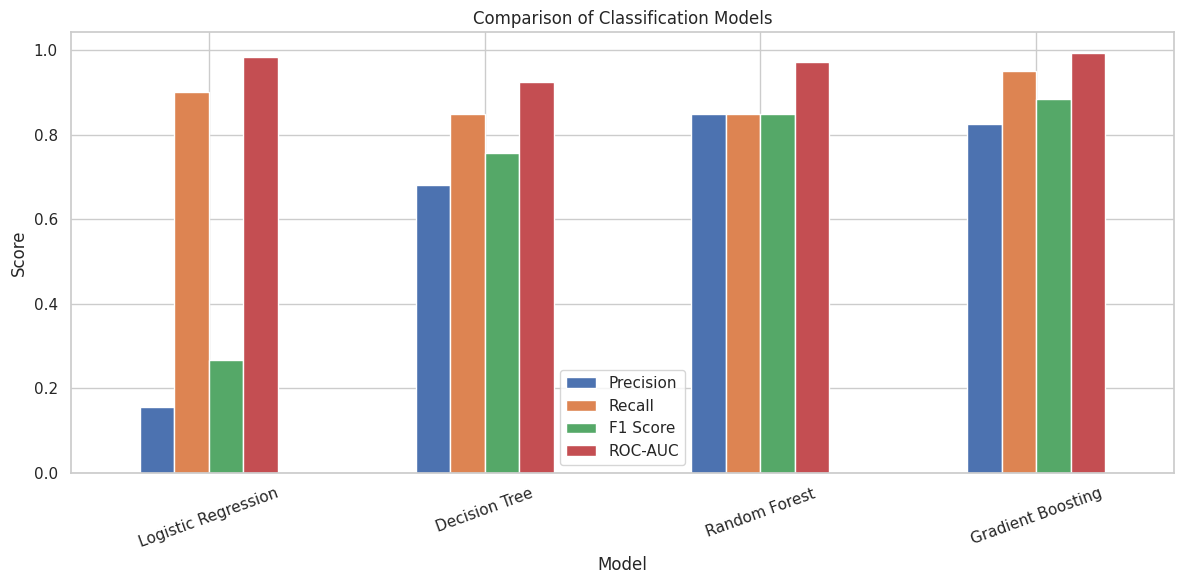

In [ ]:
# 53. Model Performance Comparison

comparison_metrics = [
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

evaluation_df.set_index("Model")[comparison_metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

## 54. Final Observations

The analysis shows that credit card fraud detection is a highly imbalanced classification problem. Exploratory data analysis helped identify differences in transaction patterns between legitimate and fraudulent transactions.

Multiple machine learning models were trained and evaluated using precision, recall, F1-score, ROC-AUC, and precision-recall analysis. The comparison provides a broader understanding of model performance rather than relying on accuracy alone.

The error analysis also highlights the importance of reducing false negatives because undetected fraudulent transactions can be significant in a fraud detection system.

## 55. Limitations

- The dataset contains anonymized features, which limits direct interpretation of individual variables.
- Fraudulent transactions represent a very small portion of the dataset.
- SMOTE generates synthetic minority samples and may not perfectly represent real fraudulent transactions.
- Model performance may change when applied to real-world financial transaction data.
- The dataset does not provide detailed customer or merchant information.
- Fraud patterns can change over time, requiring models to be periodically retrained.

## 56. Future Scope

- Implement advanced ensemble and boosting techniques.
- Perform hyperparameter optimization.
- Explore deep learning approaches for fraud detection.
- Develop real-time fraud detection pipelines.
- Implement model monitoring and periodic retraining.
- Deploy the model using Flask, FastAPI, or Streamlit.
- Integrate explainable AI techniques to improve model interpretability.
- Evaluate the system on newer and more diverse transaction datasets.

## 57. Conclusion

This project developed a machine learning-based approach for detecting fraudulent credit card transactions. The project covered data exploration, preprocessing, class imbalance handling, model training, evaluation, feature importance analysis, and error analysis.

Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting models were evaluated using multiple performance metrics. The complete analysis demonstrates how machine learning can be applied to identify potentially fraudulent transactions while considering the challenges associated with highly imbalanced data.

The project provides a foundation for developing more advanced and deployable fraud detection systems in the future.